# Задача 3. AVL

**Объяснение решения**

AVL - дерево поиска, в котором для каждого узла высота левого и правого поддеревьев отличаются не больше чем на `1`.

В узле храним `value`, `left`, `right` и `height`. Допустимые значения баланса: `-1`, `0`, `1`.

Вставка: Рекурсивно ищем место, как в обычном BST. При возврате пересчитываем высоты и при необходимости выполняем поворот.

Удаление: Сначала находим узел. Если детей нет, удаляем его. Если ребенок один, возвращаем этого ребёнка. Если детей два, заменяем значение минимумом правого поддерева и удаляем этот минимум из его прежнего места. После удаления пересчитываем высоты и восстанавливаем баланс до корня.

Поиск: Если значение равно текущему, возвращаем `True`. Если меньше, идем влево, иначе - вправо. Если дошли до `None`, возвращаем `False`.

| Случай | Условие | Поворот |
|---|---|---|
| LL | Баланс узла `> 1`, баланс левого ребенка `>= 0` | Правый |
| LR | Баланс узла `> 1`, баланс левого ребенка `< 0` | Левый у ребенка, затем правый у узла |
| RR | Баланс узла `< -1`, баланс правого ребенка `<= 0` | Левый |
| RL | Баланс узла `< -1`, баланс правого ребенка `> 0` | Правый у ребенка, затем левый у узла |

**Решение**

In [1]:
from __future__ import annotations

from dataclasses import dataclass

@dataclass
class Node:
    value: int
    left: Node | None = None
    right: Node | None = None
    height: int = 1


class AVL:

    def __init__(self, values: Iterable[int] = ()) -> None:
        self.root: Node | None = None
        for value in values:
            self.insert(value)

    def insert(self, value: int) -> None:
        self.root = self._insert(self.root, value)

    def delete(self, value: int) -> None:
        self.root = self._delete(self.root, value)

    def search(self, value: int) -> bool:
        return self._search(self.root, value)

    def _height(self, node: Node | None) -> int:
        return 0 if node is None else node.height

    def _update_height(self, node: Node) -> None:
        node.height = 1 + max(self._height(node.left), self._height(node.right))

    def _balance_factor(self, node: Node | None) -> int:
        if node is None:
            return 0
        return self._height(node.left) - self._height(node.right)

    def _rotate_right(self, node: Node) -> Node:
        new_root = node.left
        middle = new_root.right

        new_root.right = node
        node.left = middle

        self._update_height(node)
        self._update_height(new_root)
        return new_root

    def _rotate_left(self, node: Node) -> Node:
        new_root = node.right
        middle = new_root.left

        new_root.left = node
        node.right = middle

        self._update_height(node)
        self._update_height(new_root)
        return new_root

    def _rebalance(self, node: Node) -> Node:
        self._update_height(node)
        balance = self._balance_factor(node)

        if balance > 1:
            if self._balance_factor(node.left) < 0:
                node.left = self._rotate_left(node.left)
            return self._rotate_right(node)

        if balance < -1:
            if self._balance_factor(node.right) > 0:
                node.right = self._rotate_right(node.right)
            return self._rotate_left(node)

        return node

    def _insert(self, node: Node | None, value: int) -> Node:
        if node is None:
            return Node(value)

        if value < node.value:
            node.left = self._insert(node.left, value)
        elif value > node.value:
            node.right = self._insert(node.right, value)
        else:
            return node

        return self._rebalance(node)

    def _minimum(self, node: Node) -> Node:
        if node.left is None:
            return node
        return self._minimum(node.left)

    def _delete(self, node: Node | None, value: int) -> Node | None:
        if node is None:
            return None

        if value < node.value:
            node.left = self._delete(node.left, value)
        elif value > node.value:
            node.right = self._delete(node.right, value)
        else:
            if node.left is None:
                return node.right
            if node.right is None:
                return node.left

            successor = self._minimum(node.right)
            node.value = successor.value
            node.right = self._delete(node.right, successor.value)

        return self._rebalance(node)

    def _search(self, node: Node | None, value: int) -> bool:
        if node is None:
            return False
        if value == node.value:
            return True
        if value < node.value:
            return self._search(node.left, value)
        return self._search(node.right, value)

**Пример**

Вставим `30`, `10`, `20`. При последней вставке возникает случай LR: у `30` перевешивает левое поддерево, а у его левого ребёнка `10` - правое.

Для рисунков использую функцию из прошлой работы с деревьями от кодекса.

In [2]:
from html import escape
from IPython.display import HTML, Markdown, SVG, display


def tree_svg(tree, title="AVL-дерево"):
    """SVG-схема небольшого дерева; расположение узлов задаёт inorder."""
    if tree.root is None:
        return (
            '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 720 140">'
            '<rect width="720" height="140" rx="16" fill="#f8fafc"/>'
            f'<text x="24" y="36" font-family="sans-serif" font-size="20" '
            f'fill="#0f172a">{escape(title)}</text>'
            '<text x="360" y="95" text-anchor="middle" font-family="sans-serif" '
            'font-size="18" fill="#475569">Пустое дерево: root = None</text></svg>'
        )

    ordered = []

    def collect(node, depth):
        if node is None:
            return
        collect(node.left, depth + 1)
        ordered.append((node, depth))
        collect(node.right, depth + 1)

    collect(tree.root, 0)

    width, margin, level_gap, radius = 720, 48, 88, 22
    height = 135 + level_gap * max(depth for _, depth in ordered)
    positions = {}
    for index, (node, depth) in enumerate(ordered):
        x = width / 2 if len(ordered) == 1 else (
            margin + index * (width - 2 * margin) / (len(ordered) - 1)
        )
        positions[id(node)] = (x, 85 + level_gap * depth)

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
        f'width="{width}" role="img" aria-label="{escape(title, quote=True)}">',
        f'<rect width="{width}" height="{height}" rx="16" fill="#f8fafc"/>',
        f'<text x="24" y="34" font-family="sans-serif" font-size="20" '
        f'font-weight="600" fill="#0f172a">{escape(title)}</text>',
    ]
    for node, _ in ordered:
        x1, y1 = positions[id(node)]
        for child, label in ((node.left, "L"), (node.right, "R")):
            if child is None:
                continue
            x2, y2 = positions[id(child)]
            parts.append(
                f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" '
                'stroke="#94a3b8" stroke-width="2.5"/>'
            )
            parts.append(
                f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 7}" '
                'text-anchor="middle" font-family="sans-serif" font-size="13" '
                'fill="#475569" stroke="#f8fafc" stroke-width="4" '
                f'paint-order="stroke">{label}</text>'
            )
    for node, _ in ordered:
        x, y = positions[id(node)]
        left_height = 0 if node.left is None else node.left.height
        right_height = 0 if node.right is None else node.right.height
        balance = left_height - right_height
        parts.extend([
            f'<circle cx="{x}" cy="{y}" r="{radius}" fill="#e0e7ff" '
            'stroke="#4f46e5" stroke-width="2"/>',
            f'<text x="{x}" y="{y + 6}" text-anchor="middle" '
            'font-family="sans-serif" font-size="18" font-weight="600" '
            f'fill="#312e81">{node.value}</text>',
            f'<text x="{x}" y="{y + 40}" text-anchor="middle" '
            'font-family="sans-serif" font-size="12" fill="#475569" '
            'stroke="#f8fafc" stroke-width="3" paint-order="stroke">'
            f'h={node.height}, b={balance}</text>',
        ])
    parts.append('</svg>')
    return ''.join(parts)

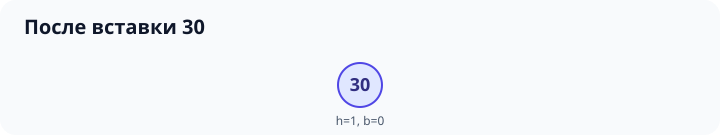

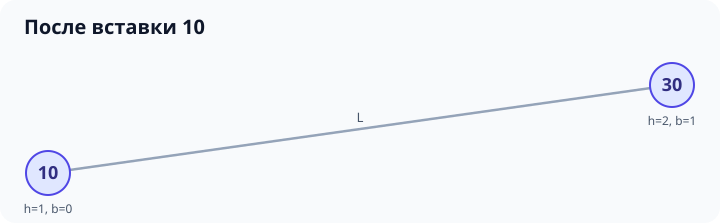

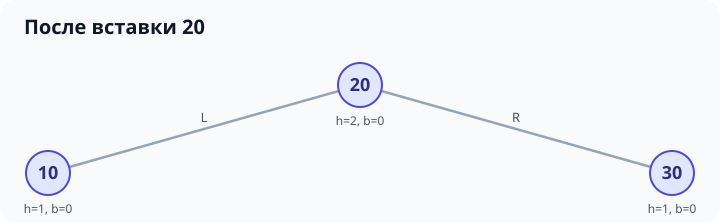

In [3]:
tree = AVL()

for value in [30, 10, 20]:
    tree.insert(value)
    display(SVG(tree_svg(tree, f"После вставки {value}")))

**Пошаговая балансировка после вставки `20`.**

| Шаг | Что происходит | Результат |
|---|---|---|
| 1 | `20 < 30`, затем `20 > 10` | Новый узел становится правым ребенком `10` |
| 2 | Обновляем высоты при возврате | Баланс `10` равен `-1`, баланс `30` равен `2` |
| 3 | Делаем левый поворот у `10` | `20` становится левым ребенком `30`, а `10` - левым ребенком `20` |
| 4 | Делаем правый поворот у `30` | Новый корень - `20`, его дети - `10` и `30` |
| 5 | Обновляем высоты | У листьев высота `1`, у корня - `2`. Баланс всех узлов равен `0` |

Теперь удалим `5` из дерева `[4, 2, 5, 1, 3]`.
После удаления у узла `4` высота слева равна `2`, справа - `0`.
Баланс равен `2`, а у левого ребёнка `2` баланс равен `0`.
Делаем один правый поворот. Новый корень - `2`, узел `3` переходит в левое
поддерево узла `4`.

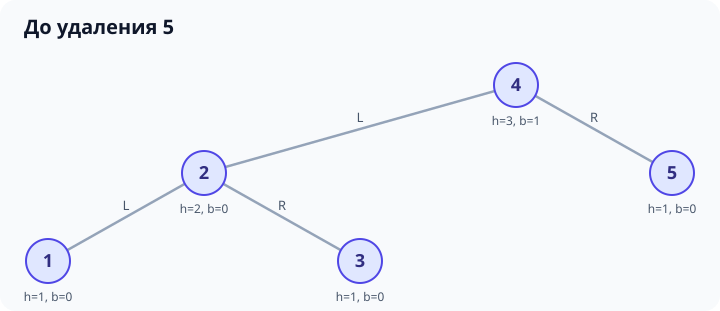

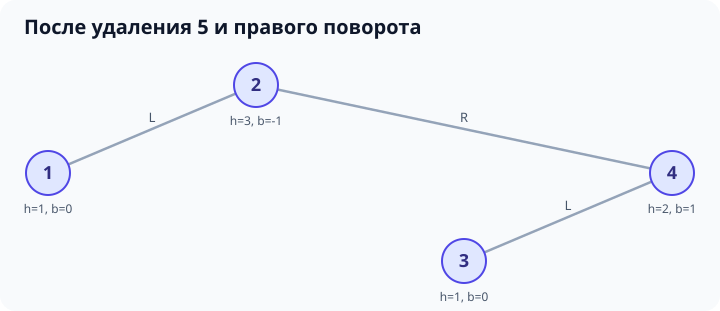

Поиск 3: True
Поиск 5: False


In [4]:
tree = AVL([4, 2, 5, 1, 3])
display(SVG(tree_svg(tree, "До удаления 5")))

tree.delete(5)
display(SVG(tree_svg(tree, "После удаления 5 и правого поворота")))

print("Поиск 3:", tree.search(3))
print("Поиск 5:", tree.search(5))

**Сложность**

Пусть `n` - число узлов. Высота AVL-дерева равна `O(log n)`. Сравнение значений - `O(1)`.

| Операция | Время | Дополнительная память |
|---|---|---|
| Вставка | `O(log n)` | `O(log n)` для рекурсии |
| Удаление | `O(log n)` | `O(log n)` для рекурсии |
| Поиск | `O(log n)` | `O(log n)` для рекурсии |
| Один поворот | `O(1)` | `O(1)` |

Вставка и поиск проходят за `O(log n)`, так как на каждом шаге количество опций, куда пойти дальше, сокращается вдвое.

Высоты хранятся в узлах, поэтому обновление высоты и проверка баланса занимают `O(1)`. На обратном пути проверяем не больше `O(log n)` узлов.

**Тесты**

In [5]:
import random
import unittest
from copy import deepcopy
from itertools import permutations


class TestAVL(unittest.TestCase):
    def check_tree(self, tree, expected):
        values = []
        visited = set()

        def check(node, lower=None, upper=None):
            if node is None:
                return 0

            self.assertNotIn(id(node), visited)
            visited.add(id(node))

            if lower is not None:
                self.assertGreater(node.value, lower)
            if upper is not None:
                self.assertLess(node.value, upper)

            left_height = check(node.left, lower, node.value)
            values.append(node.value)
            right_height = check(node.right, node.value, upper)

            actual_height = 1 + max(left_height, right_height)
            self.assertEqual(node.height, actual_height)
            self.assertLessEqual(abs(left_height - right_height), 1)
            return actual_height

        check(tree.root)
        self.assertEqual(values, sorted(set(expected)))

    def check_insert_rotation(self, values):
        tree = AVL()
        expected = set()
        for value in values:
            tree.insert(value)
            expected.add(value)
            self.check_tree(tree, expected)

        self.assertEqual(tree.root.value, 20)
        self.assertEqual(tree.root.left.value, 10)
        self.assertEqual(tree.root.right.value, 30)

    def test_empty(self):
        tree = AVL()
        self.assertIsNone(tree.root)
        self.assertIs(tree.search(10), False)
        tree.delete(10)
        self.check_tree(tree, [])

    def test_single(self):
        tree = AVL()
        tree.insert(7)
        self.assertIs(tree.search(7), True)
        self.check_tree(tree, [7])

        tree.delete(7)
        self.assertIsNone(tree.root)
        self.assertIs(tree.search(7), False)
        self.check_tree(tree, [])

    def test_insert_ll(self):
        self.check_insert_rotation([30, 20, 10])

    def test_insert_rr(self):
        self.check_insert_rotation([10, 20, 30])

    def test_insert_lr(self):
        self.check_insert_rotation([30, 10, 20])

    def test_insert_rl(self):
        self.check_insert_rotation([10, 30, 20])

    def test_duplicates(self):
        tree = AVL([5, 3, 7, 5, 3, 5])
        self.check_tree(tree, [3, 5, 7])

        tree.delete(5)
        self.assertIs(tree.search(5), False)
        self.check_tree(tree, [3, 7])

        tree.delete(5)
        self.check_tree(tree, [3, 7])

    def test_search(self):
        values = [10, 5, 15, 2, 7, 12, 20]
        tree = AVL(values)
        before = deepcopy(tree.root)

        for value in values:
            self.assertIs(tree.search(value), True)
        for value in [-1, 0, 6, 11, 13, 100]:
            self.assertIs(tree.search(value), False)

        self.assertEqual(tree.root, before)
        self.check_tree(tree, values)

    def test_delete_leaf(self):
        values = [20, 10, 30, 5, 15, 25, 35]
        tree = AVL(values)
        expected = set(values)

        for value in [5, 15, 35]:
            tree.delete(value)
            expected.remove(value)
            self.assertIs(tree.search(value), False)
            self.check_tree(tree, expected)

    def test_delete_one_child(self):
        cases = [
            ([10, 5], 10),
            ([10, 15], 10),
            ([20, 10, 30, 5], 10),
            ([20, 10, 30, 15], 10),
        ]
        for values, deleted in cases:
            with self.subTest(values=values, deleted=deleted):
                tree = AVL(values)
                tree.delete(deleted)
                self.check_tree(tree, set(values) - {deleted})
                self.assertIs(tree.search(deleted), False)

    def test_delete_two_children(self):
        cases = [
            [20, 10, 40, 5, 15, 30, 50, 35],
            [20, 10, 30, 5, 15, 35],
        ]
        for values in cases:
            with self.subTest(values=values):
                tree = AVL(values)
                self.assertEqual(tree.root.value, 20)
                self.assertIsNotNone(tree.root.left)
                self.assertIsNotNone(tree.root.right)

                tree.delete(20)
                self.assertIs(tree.search(20), False)
                self.check_tree(tree, set(values) - {20})

    def test_delete_missing(self):
        values = [5, 2, 8, 1, 3, 7, 9]
        tree = AVL(values)
        before = deepcopy(tree.root)

        for value in [0, 4, 6, 10]:
            tree.delete(value)
            self.assertEqual(tree.root, before)
            self.check_tree(tree, values)

    def test_delete_root_repeatedly(self):
        tree = AVL(range(40))
        expected = set(range(40))

        while tree.root is not None:
            value = tree.root.value
            tree.delete(value)
            expected.remove(value)
            self.assertIs(tree.search(value), False)
            self.check_tree(tree, expected)

        self.assertEqual(expected, set())

    def test_delete_rotate_right_zero_child_balance(self):
        tree = AVL([4, 2, 5, 1, 3])
        tree.delete(5)
        self.assertEqual(tree.root.value, 2)
        self.check_tree(tree, [1, 2, 3, 4])

    def test_delete_rotate_left_zero_child_balance(self):
        tree = AVL([2, 1, 4, 3, 5])
        tree.delete(1)
        self.assertEqual(tree.root.value, 4)
        self.check_tree(tree, [2, 3, 4, 5])

    def test_delete_lr(self):
        values = [5, 2, 8, 1, 4, 9, 3]
        tree = AVL(values)
        tree.delete(9)
        self.assertEqual(tree.root.value, 4)
        self.check_tree(tree, set(values) - {9})

    def test_delete_rl(self):
        values = [5, 2, 8, 1, 6, 9, 7]
        tree = AVL(values)
        tree.delete(1)
        self.assertEqual(tree.root.value, 6)
        self.check_tree(tree, set(values) - {1})

    def test_sorted_inputs(self):
        cases = [list(range(300)), list(range(299, -1, -1))]
        for values in cases:
            tree = AVL()
            expected = set()
            for value in values:
                tree.insert(value)
                expected.add(value)
                self.check_tree(tree, expected)

    def test_negative_zero_and_large_values(self):
        large = 10 ** 100
        values = [0, -10, 10, -large, large, -1, 1]
        tree = AVL()
        expected = set()

        for value in values:
            tree.insert(value)
            expected.add(value)
            self.check_tree(tree, expected)

        for value in [-10, 0, large]:
            tree.delete(value)
            expected.remove(value)
            self.check_tree(tree, expected)

    def test_delete_all_orders(self):
        values = list(range(32))
        shuffled = values.copy()
        random.Random(42).shuffle(shuffled)

        for order in [values, values[::-1], shuffled]:
            tree = AVL(values)
            expected = set(values)

            for value in order:
                tree.delete(value)
                expected.remove(value)
                self.check_tree(tree, expected)

            self.assertIsNone(tree.root)

    def test_random_operations(self):
        for seed in range(5):
            rng = random.Random(seed)
            tree = AVL()
            expected = set()

            for step in range(250):
                value = rng.randint(-40, 40)
                operation = rng.choice(["insert", "delete", "search"])

                with self.subTest(seed=seed, step=step, operation=operation, value=value):
                    if operation == "insert":
                        tree.insert(value)
                        expected.add(value)
                    elif operation == "delete":
                        tree.delete(value)
                        expected.discard(value)

                    self.assertIs(tree.search(value), value in expected)
                    self.check_tree(tree, expected)

    def test_small_sequences(self):
        orders = list(permutations(range(4)))

        for insertion_order in orders:
            for deletion_order in orders:
                with self.subTest(insert=insertion_order, delete=deletion_order):
                    tree = AVL(insertion_order)
                    expected = set(insertion_order)
                    self.check_tree(tree, expected)

                    for value in deletion_order:
                        tree.delete(value)
                        expected.remove(value)
                        self.check_tree(tree, expected)

In [6]:
suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestAVL)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), "Некоторые тесты завершились ошибкой"
print(f"Успешно пройдено тестов: {test_result.testsRun}")

test_delete_all_orders (__main__.TestAVL.test_delete_all_orders) ... ok
test_delete_leaf (__main__.TestAVL.test_delete_leaf) ... ok
test_delete_lr (__main__.TestAVL.test_delete_lr) ... ok
test_delete_missing (__main__.TestAVL.test_delete_missing) ... ok
test_delete_one_child (__main__.TestAVL.test_delete_one_child) ... ok
test_delete_rl (__main__.TestAVL.test_delete_rl) ... ok
test_delete_root_repeatedly (__main__.TestAVL.test_delete_root_repeatedly) ... ok
test_delete_rotate_left_zero_child_balance (__main__.TestAVL.test_delete_rotate_left_zero_child_balance) ... ok
test_delete_rotate_right_zero_child_balance (__main__.TestAVL.test_delete_rotate_right_zero_child_balance) ... ok
test_delete_two_children (__main__.TestAVL.test_delete_two_children) ... ok
test_duplicates (__main__.TestAVL.test_duplicates) ... ok
test_empty (__main__.TestAVL.test_empty) ... ok
test_insert_ll (__main__.TestAVL.test_insert_ll) ... ok
test_insert_lr (__main__.TestAVL.test_insert_lr) ... ok
test_insert_rl (__

Успешно пройдено тестов: 22
